# Daily Stock Market Prediction

In [37]:
!rm -rf My-Daily-Python-Learning

In [38]:
!git clone -b trading_stock_market https://github.com/Jalilnkh/My-Daily-Python-Learning

Cloning into 'My-Daily-Python-Learning'...
remote: Enumerating objects: 711, done.
remote: Counting objects: 100% (282/282), done.
remote: Compressing objects: 100% (276/276), done.
remote: Total 711 (delta 132), reused 2 (delta 2), pack-reused 429 (from 2)
Receiving objects: 100% (711/711), 25.10 MiB | 62.22 MiB/s, done.
Resolving deltas: 100% (374/374), done.


In [39]:
%%bash
cd "/content/My-Daily-Python-Learning/Daily Stock Market Prediction"
python3 src/download_nvda_related_100.py \
    --start 2018-01-01 \
    --end 2026-11-06

Fetching 1-10/102: NVDA, AMD, AVGO, MRVL, MU, INTC, TSM, ASML, AMAT, LRCX
Fetching 11-20/102: KLAC, ARM, QCOM, ON, NXPI, MCHP, MPWR, ADI, TXN, ALGM
Fetching 21-30/102: COHU, ACLS, ONTO, TER, LSCC, FORM, RMBS, AMKR, SNPS, CDNS
Fetching 31-40/102: ANET, CSCO, CIEN, LITE, COHR, AAOI, CRDO, ALAB, GLW, APH
Fetching 41-50/102: TEL, KEYS, FN, CALX, BELFB, SMCI, DELL, HPE, IBM, NTAP
Fetching 51-60/102: WDC, STX, SNDK, TSSI, FLEX, JBL, CRWV, NBIS, APLD, IREN
Fetching 61-70/102: CIFR, WULF, HUT, BTDR, EQIX, DLR, IRM, RXT, VRT, ETN
Fetching 71-80/102: NVT, MOD, GEV, CEG, VST, TLN, NRG, GNRC, POWL, EMR
Fetching 81-90/102: HUBB, AES, D, PWR, EME, FIX, MTZ, DY, STRL, IESC
Fetching 91-100/102: APG, PRIM, MYRG, ACM, WCC, MSFT, AMZN, GOOGL, META, ORCL
Fetching 101-102/102: SPY, QQQ
Finished: 100/100 stocks downloaded
OHLCV observations: 207,224; model panel observations: 202,776
Files saved in: /content/My-Daily-Python-Learning/Daily Stock Market Prediction/src/output
IMPORTANT: Co-movement during an e

In [40]:
import os
output_dir = "/content/My-Daily-Python-Learning/Daily Stock Market Prediction/src/output"
if os.path.exists(output_dir):
    print(os.listdir(output_dir))
else:
    print("Output directory not found.")

['download_status.csv', 'stock_training_panel.csv', 'nvidia_election_event_screen.csv', 'prices_100_stocks_daily.csv']


In [41]:
import pandas as pd
import glob
import matplotlib.pyplot as plt

# Find all CSV files in the output directory
csv_files = glob.glob(output_dir + "/*.csv")
print(f"Found {len(csv_files)} CSV files:", csv_files)

# Load and plot the first available dataset as an example
if csv_files:
    df = pd.read_csv(csv_files[0])
    print("\nData Columns:", df.columns)
    display(df.head())

    # Plot close prices for a few tickers if structured as panel data
    if 'Date' in df.columns or 'date' in df.columns:
        date_col = 'Date' if 'Date' in df.columns else 'date'
        df[date_col] = pd.to_datetime(df[date_col])

        # If the dataset contains multiple tickers
        if 'Ticker' in df.columns or 'ticker' in df.columns:
            ticker_col = 'Ticker' if 'Ticker' in df.columns else 'ticker'
            unique_tickers = df[ticker_col].unique()
            print(f"Unique tickers in dataset: {unique_tickers[:10]}...")

            # Plot top 3 tickers
            plt.figure(figsize=(12, 6))
            for ticker in unique_tickers[:3]:
                ticker_df = df[df[ticker_col] == ticker].sort_values(by=date_col)
                close_col = 'Close' if 'Close' in df.columns else ('close' if 'close' in df.columns else df.columns[4])
                plt.plot(ticker_df[date_col], ticker_df[close_col], label=ticker)
            plt.title('Stock Close Prices Over Time')
            plt.xlabel('Date')
            plt.ylabel('Price ($)')
            plt.legend()
            plt.grid(True)
            plt.show()
else:
    print("No CSV files found to plot.")

Found 4 CSV files: ['/content/My-Daily-Python-Learning/Daily Stock Market Prediction/src/output/download_status.csv', '/content/My-Daily-Python-Learning/Daily Stock Market Prediction/src/output/stock_training_panel.csv', '/content/My-Daily-Python-Learning/Daily Stock Market Prediction/src/output/nvidia_election_event_screen.csv', '/content/My-Daily-Python-Learning/Daily Stock Market Prediction/src/output/prices_100_stocks_daily.csv']

Data Columns: Index(['ticker', 'status', 'rows', 'note'], dtype='object')


,ticker,status,rows,note
0,NVDA,OK,2224,NaN
1,AMD,OK,2224,NaN
2,AVGO,OK,2224,NaN
3,MRVL,OK,2224,NaN
4,MU,OK,2224,NaN


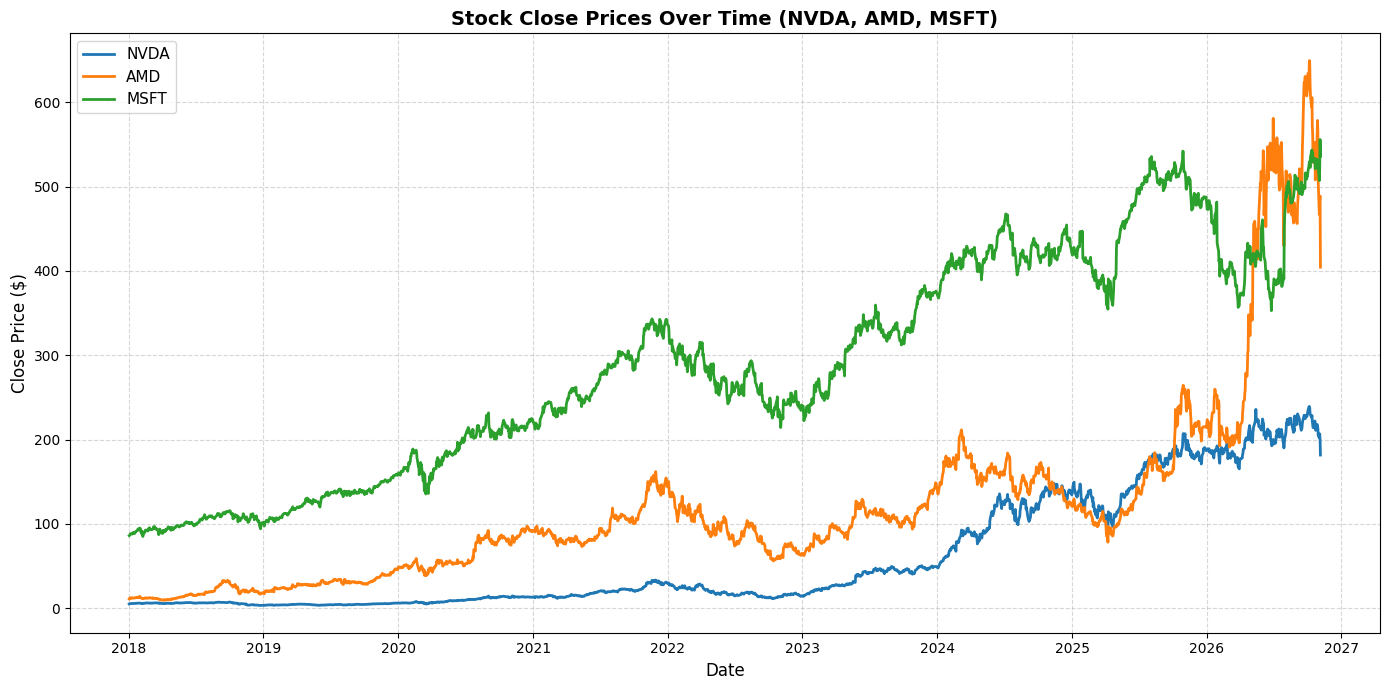

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the specific panel dataset
file_path = "/content/My-Daily-Python-Learning/Daily Stock Market Prediction/src/output/stock_training_panel.csv"
df_panel = pd.read_csv(file_path)
df_panel['date'] = pd.to_datetime(df_panel['date'])

# Filter to plot a few highly recognizable tickers
target_tickers = ['NVDA', 'AMD', 'MSFT']
plt.figure(figsize=(14, 7))

for ticker in target_tickers:
    ticker_data = df_panel[df_panel['ticker'] == ticker].sort_values('date')
    if not ticker_data.empty:
        plt.plot(ticker_data['date'], ticker_data['close'], label=ticker, linewidth=2)

plt.title('Stock Close Prices Over Time (NVDA, AMD, MSFT)', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Close Price ($)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

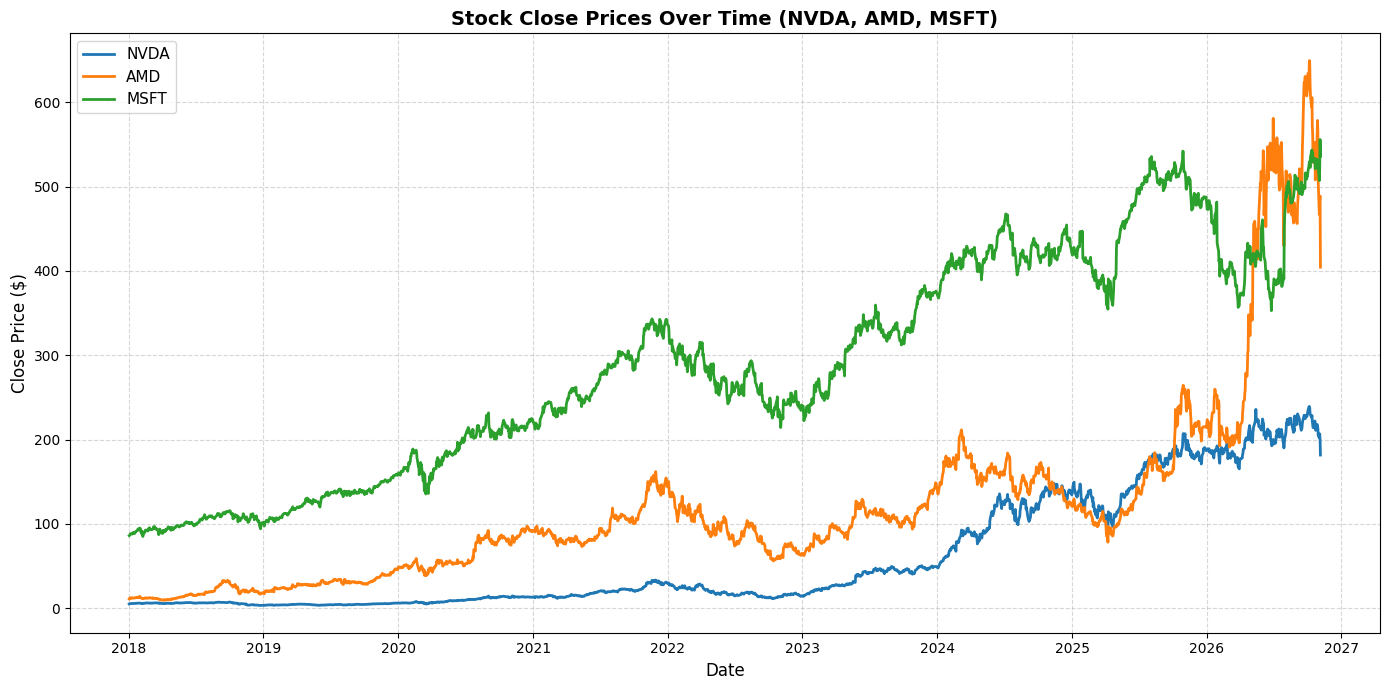

In [43]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the specific panel dataset
file_path = "/content/My-Daily-Python-Learning/Daily Stock Market Prediction/src/output/stock_training_panel.csv"
df_panel = pd.read_csv(file_path)
df_panel['date'] = pd.to_datetime(df_panel['date'])

# Filter to plot a few highly recognizable tickers
target_tickers = ['NVDA', 'AMD', 'MSFT']
plt.figure(figsize=(14, 7))

for ticker in target_tickers:
    ticker_data = df_panel[df_panel['ticker'] == ticker].sort_values('date')
    if not ticker_data.empty:
        plt.plot(ticker_data['date'], ticker_data['close'], label=ticker, linewidth=2)

plt.title('Stock Close Prices Over Time (NVDA, AMD, MSFT)', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Close Price ($)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Train

In [44]:
!python3 "/content/My-Daily-Python-Learning/Daily Stock Market Prediction/train.py" --ticker NVDA


NVDA: forecast made after 2026-11-05 closing price 181.60
trading_session_ahead  predicted_adjusted_return_pct  illustrative_future_close
                  T+1                         1.1997                   183.7786
                  T+2                         0.4627                   182.4403
                  T+3                         0.5641                   182.6244
                  T+4                         0.9175                   183.2661
                  T+5                         0.9251                   183.2800
Test MAE (percentage points; lower is better), model versus no-change baseline:
 horizon_trading_days  test_mae_pct_points  no_change_mae_pct_points  mae_improvement_vs_no_change_pct  test_up_down_accuracy_pct
                    1               1.7699                    1.7671                             -0.16                      48.77
                    2               2.4885                    2.4866                             -0.07                   

#Predict

In [45]:
!pip install -q lightgbm pandas numpy scikit-learn matplotlib exchange-calendars

In [46]:
!python3 "/content/My-Daily-Python-Learning/Daily Stock Market Prediction/predict.py" --ticker NVDA

Last actual close: 2026-11-05 = 181.60
      date  horizon  predicted_return_pct  predicted_close
2026-11-06        1              1.199659       183.778586
2026-11-09        2              0.462713       182.440294
2026-11-10        3              0.564095       182.624403
2026-11-11        4              0.917454       183.266102
2026-11-12        5              0.925132       183.280046
Charts and CSV saved to: /content/My-Daily-Python-Learning/Daily Stock Market Prediction/src/output/lightgbm_weekly/NVDA
